In [3]:
import matplotlib.pyplot as plt
#import cartopy.crs as ccrs
import harmonica as hm
import numpy as np
from sklearn.linear_model import LinearRegression
import pandas as pd
import netCDF4 
import xarray as xr
import verde as vd
import pyproj 
#import pygmt

In [9]:
#Loadind GDF file from ICGM#
#To download:
#go to http://icgem.gfz-potsdam.de/calcgrid
#choose "Model selection (here we are using GOCO03s), 
#choose Functionalbselection (here we are using gravity_disturbance_sa)
#choose area and click on start computation
#after calculation is complete, click on download grid

GD_sa_GOCO06s = hm.load_icgem_gdf('gravity_disturbance_sa_GOCO06s_01degree.gdf') #gravity disturbance sa
GD_sa_GOCO06s

C:\Users\Renata\miniconda3\envs\pygmt\Lib\site-packages\verde\blockreduce.py:177: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  columns = {"data{}".format(i): comp.ravel() for i, comp in enumerate(data)}
C:\Users\Renata\miniconda3\envs\pygmt\Lib\site-packages\verde\blockreduce.py:179: FutureWarning: The provided callable <function mean at 0x0000014EF155CB80> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  blocked = pd.DataFrame(columns).groupby("block").aggregate(reduction)
C:\Users\Renata\miniconda3\envs\pygmt\Lib\site-packages\verde\blockreduce.py:236: FutureWarning: The provided callable <function mean at 0x0000014EF155CB80> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used direct

<xarray.Dataset> Size: 3MB
Dimensions:              (x: 607, y: 607)
Coordinates:
  * x                    (x) float64 5kB -3.333e+06 -3.322e+06 ... 3.333e+06
  * y                    (y) float64 5kB -3.333e+06 -3.322e+06 ... 3.333e+06
Data variables:
    gravity_disturbance  (y, x) float64 3MB nan nan nan nan ... nan nan nan nan

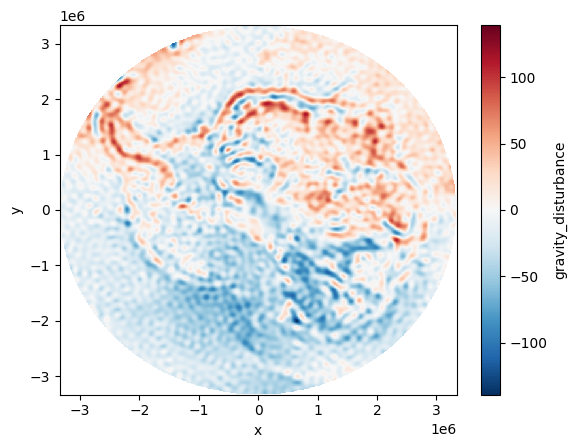

In [3]:
projection = pyproj.Proj("epsg:3031")

# Do the projection while setting the output grid spacing (in projected
# meters). Set the coordinates names to x and y since they aren't really
# "northing" or "easting".
polar_data = vd.project_grid(
    GD_sa_GOCO06s.gravity_disturbance_sa, projection, spacing=11e3, dims=("y", "x")
)
polar_data = polar_data.to_dataset(name = "gravity_disturbance")
polar_data.gravity_disturbance.plot()
polar_data


In [4]:
dset =xr.load_dataset('BedMachineAntarctica_v3.nc')
dset

<xarray.Dataset> Size: 4GB
Dimensions:    (x: 13333, y: 13333)
Coordinates:
  * x          (x) int32 53kB -3333000 -3332500 -3332000 ... 3332500 3333000
  * y          (y) int32 53kB 3333000 3332500 3332000 ... -3332500 -3333000
Data variables:
    mapping    |S1 1B b''
    mask       (y, x) int8 178MB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    firn       (y, x) float32 711MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    surface    (y, x) float32 711MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    thickness  (y, x) float32 711MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    bed        (y, x) float32 711MB -5.916e+03 -5.92e+03 ... -3.664e+03
    errbed     (y, x) float32 711MB nan nan nan nan nan ... nan nan nan nan nan
    source     (y, x) int8 178MB 1 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1 1 1
    dataid     (y, x) int8 178MB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    geoid      (y, x) int16 356MB -1 -1 -1 -1 -1 -1 ... -19 -19 -19 -19 -19 -19
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

In [5]:
dset["bed_ell"]=dset.bed + dset.geoid
dset["ice_surface"]= dset.surface + dset.geoid  
dset["ice_base"]= dset.surface - dset.thickness 

In [6]:
###GROUNDED ICE###
dset["ice_top"] = xr.where((dset.mask ==2) | (dset.mask == 4), dset.ice_surface, 0)
dset["ice_bottom"]= xr.where((dset.mask ==2) | (dset.mask==4), xr.where((dset.bed_ell >= 0), dset.bed_ell, 0), 0)
dset["bed_below_ell"] = xr.where((dset.mask ==2) & (dset.bed_ell < 0) & (dset.thickness > 0), dset.bed_ell, 0)
dset["bed_above_ell"] = xr.where((dset.mask ==2) & (dset.bed_ell >= 0),  dset.bed_ell,0)

In [7]:
## SEA AND FLOATING ICE WHERE ICE SURFACE IS ABOVE THE ELLIPSOID##


dset["f_ice_above_ell"] = xr.where((dset.mask ==3) & (dset.ice_surface >= 0), dset.ice_surface, 0)
dset["f_ice_below_ell"] = xr.where((dset.mask ==3) & (dset.ice_surface>=0), dset.ice_base, 0)
dset["g_below_ell"] = xr.where((dset.mask ==0) & (dset.geoid >=0), dset.geoid, 0) 
dset["g_above_ell"] = xr.where((dset.mask ==0) & (dset.geoid < 0), dset.geoid, 0) 

dset["b1"] = xr.where((dset.mask ==3) & (dset.ice_surface >=0),dset.ice_base,0) 
dset["b2"] =  xr.where((dset.mask ==0) & (dset.geoid < 0), dset.geoid, 0)    
dset["base_1"] = xr.where((dset.mask ==0), dset.b2, dset.b1) 

dset["ba1"] = xr.where((dset.mask ==3) & (dset.ice_surface >=0),dset.bed_ell,0) 
dset["bathy_1"] =  xr.where((dset.mask == 0), dset.bed_ell, dset.ba1)  


In [8]:
## SEA AND FLOATING ICE WHERE ICE SURFACE IS BELOW THE ELLIPSOID##

dset["f_ice_surface"] = xr.where((dset.mask ==3) & (dset.ice_surface <0 ), dset.ice_surface, 0)
dset["f_ice_base"] = xr.where((dset.mask ==3) & (dset.ice_surface <0 ), dset.ice_base, 0) 
dset["f_ice_bathy"] = xr.where((dset.mask ==3) & (dset.ice_surface <0 ), dset.bed_ell, 0) 

In [10]:
dset_new = dset.coarsen(dim={'x':22,'y':22},boundary='trim').mean()
dset_new = dset_new.sortby('y')
dset_new

<xarray.Dataset> Size: 51MB
Dimensions:          (y: 606, x: 606)
Coordinates:
  * x                (x) float64 5kB -3.328e+06 -3.317e+06 ... 3.327e+06
  * y                (y) float64 5kB -3.327e+06 -3.316e+06 ... 3.328e+06
Data variables: (12/29)
    mapping          |S1 1B b''
    mask             (y, x) float64 3MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    firn             (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    surface          (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    thickness        (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    bed              (y, x) float32 1MB -4.827e+03 -4.728e+03 ... -3.91e+03
    ...               ...
    base_1           (y, x) float32 1MB -16.0 -16.0 -16.0 -16.0 ... 0.0 0.0 0.0
    ba1              (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    bathy_1          (y, x) float32 1MB -4.843e+03 -4.744e+03 ... -3.866e+03
    f_ice_surface    (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    f_ice_base       (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    f_ice_bathy      (y, x) float32 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

In [11]:
coordinates = np.meshgrid(polar_data.x, polar_data.y)
coordinates.append(5000*np.ones_like(coordinates[0]))

In [12]:
#Layer 1
prisms_1 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.ice_top,
    reference=dset_new.ice_bottom,
    properties={"density": 917 * np.ones_like(dset_new.ice_top)},)


In [13]:
gravity_1 = prisms_1.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_1"] = (("y", "x"),gravity_1)


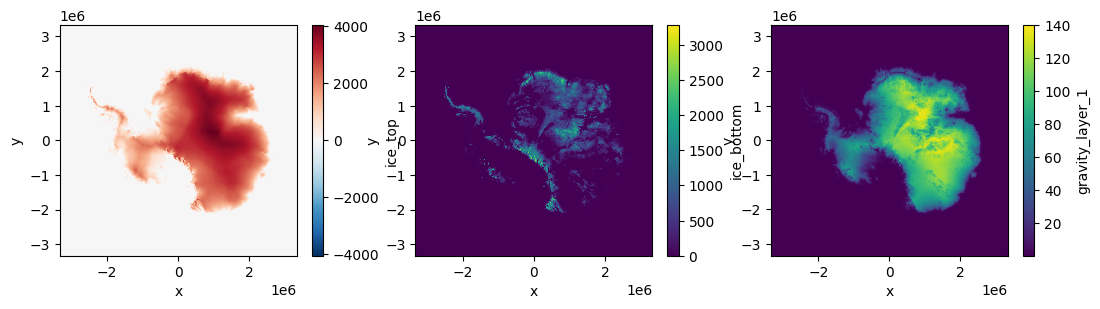

In [42]:
plt.figure(figsize = ((13, 3)))
#plt.title("FROM ICE SURFACE TO ICE BOTTOM ABOVE THE ELLIPSOID")
plt.subplot(1, 3, 1)
dset_new.ice_top.plot()
plt.subplot(1, 3, 2)
dset_new.ice_bottom.plot()
plt.subplot(1, 3, 3)
polar_data.gravity_layer_1.plot()


In [16]:
#Layer 2
prisms_2 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.bed_below_ell,
    reference= 0,
    properties={"density": (917-2670) * np.ones_like(dset_new.ice_top)},)


In [17]:
gravity_2 = prisms_2.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_2"] = (("y", "x"),gravity_2)

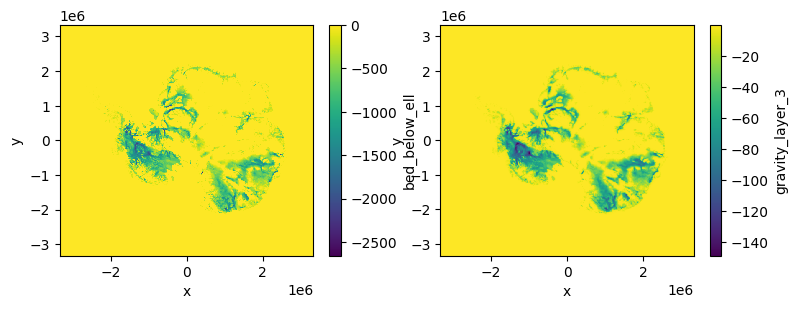

In [44]:
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.bed_below_ell.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_2.plot()

In [14]:
#Layer 3
prisms_3 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.bed_above_ell,
    reference= 0,
    properties={"density": 2670 * np.ones_like(dset_new.ice_top)},)


In [15]:
gravity_3 = prisms_3.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_2"] = (("y", "x"),gravity_3)

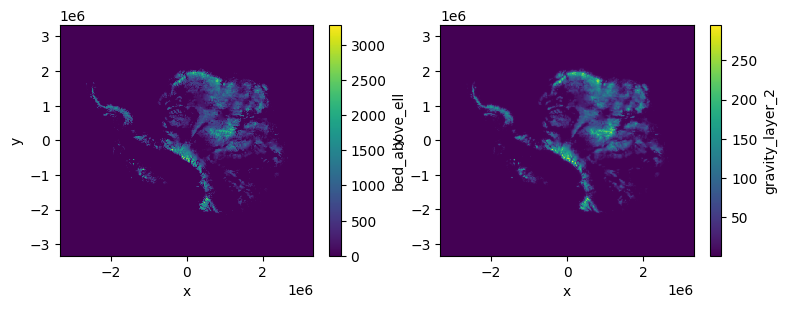

In [43]:
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.bed_above_ell.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_3.plot()

In [18]:
#Layer 4
prisms_4 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.f_ice_above_ell,
    reference= 0,
    properties={"density": (917) * np.ones_like(dset_new.ice_top)},)

In [ ]:
gravity_4 = prisms_4.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_4"] = (("y", "x"),gravity_4)

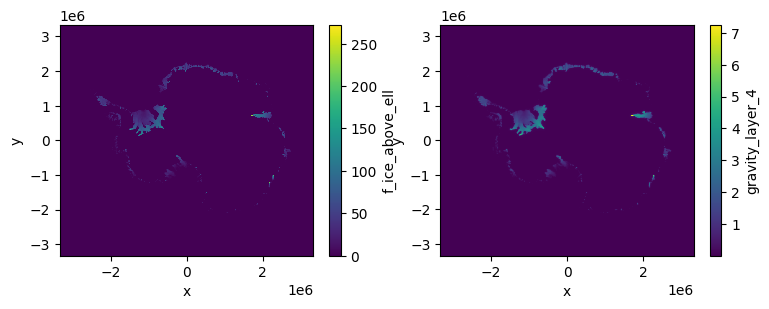

In [45]:
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.f_ice_above_ell.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_4.plot()

In [19]:
#Layer 5
prisms_5 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.f_ice_below_ell,
    reference= 0,
    properties={"density": (917-2670) * np.ones_like(dset_new.ice_top)},)

In [ ]:
gravity_5 = prisms_5.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_5"] = (("y", "x"),gravity_5)

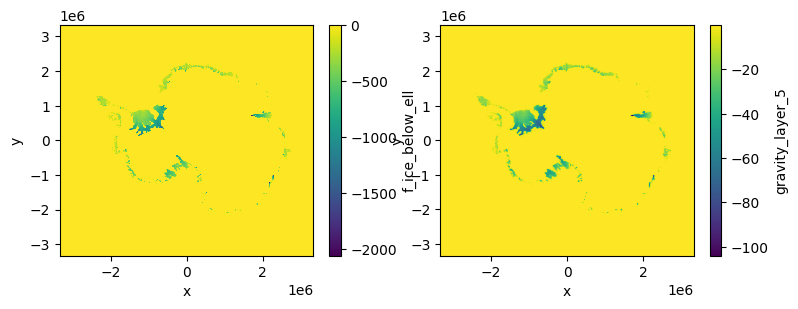

In [46]:
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.f_ice_below_ell.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_5.plot()

In [20]:
#Layer 6
prisms_6 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.g_below_ell,
    reference= 0,
    properties={"density": (-2670) * np.ones_like(dset_new.ice_top)},)

In [ ]:
gravity_6 = prisms_6.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_6"] = (("y", "x"),gravity_6)

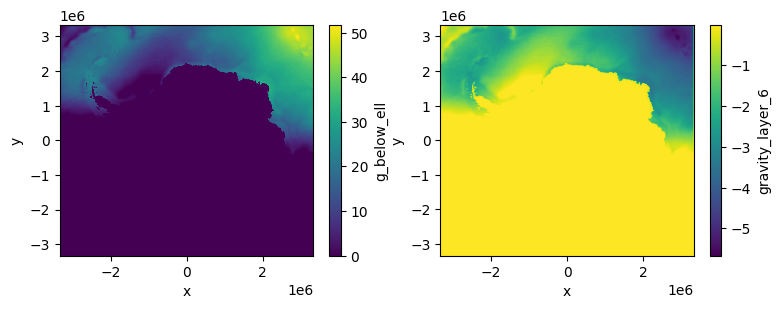

In [47]:
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.g_below_ell.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_6.plot()

In [21]:
#Layer 7
prisms_7 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.g_above_ell,
    reference= 0,
    properties={"density": (1030) * np.ones_like(dset_new.ice_top)},)

In [ ]:
gravity_7 = prisms_7.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_7"] = (("y", "x"),gravity_7)

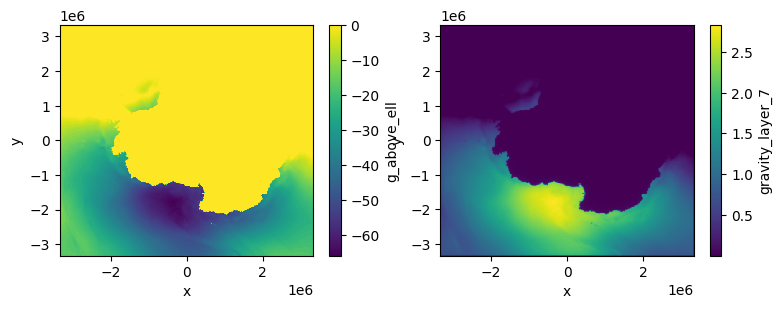

In [48]:
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.g_above_ell.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_7.plot()

In [22]:
#Layer 8
prisms_8 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.base_1,
    reference= dset_new.bathy_1,
    properties={"density": (1030-2670) * np.ones_like(dset_new.ice_top)},)

In [ ]:
gravity_8 = prisms_8.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_8"] = (("y", "x"),gravity_8)

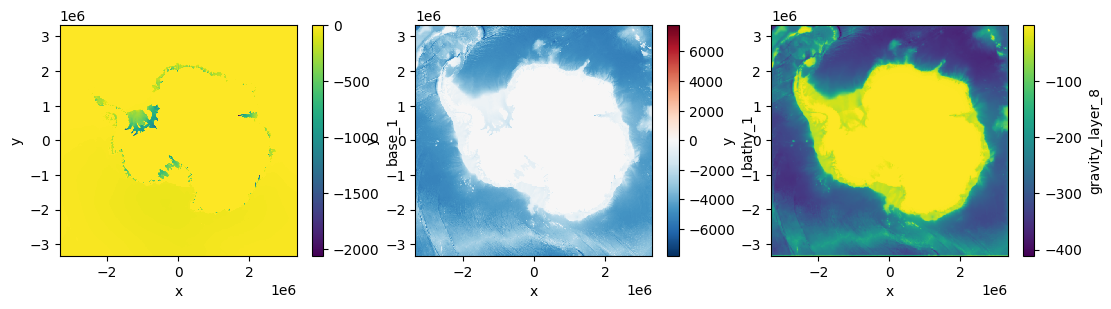

In [49]:
plt.figure(figsize = ((13, 3)))
plt.subplot(1, 3, 1)
dset_new.base_1.plot()
plt.subplot(1, 3, 2)
dset_new.bathy_1.plot()
plt.subplot(1, 3, 3)
polar_data.gravity_layer_8.plot()

In [23]:
#Layer 9
prisms_9 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.f_ice_surface,
    reference= 0,
    properties={"density": (-2670) * np.ones_like(dset_new.ice_top)},)

In [ ]:
gravity_9 = prisms_9.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_9"] = (("y", "x"),gravity_9)

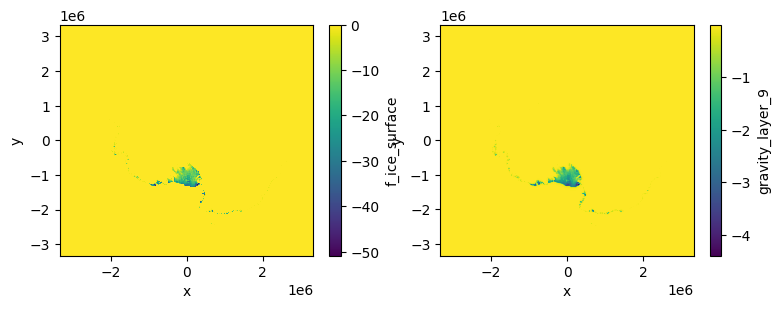

In [50]:
polar_data["gravity_layer_9"] = (("y", "x"),gravity_9)
plt.figure(figsize = ((9, 3)))
plt.subplot(1, 2, 1)
dset_new.f_ice_surface.plot()
plt.subplot(1, 2, 2)
polar_data.gravity_layer_9.plot()

In [24]:
#Layer 10
prisms_10 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.f_ice_surface,
    reference= dset_new.f_ice_base,
    properties={"density": (917-2670) * np.ones_like(dset_new.ice_top)},)

gravity_10 = prisms_10.prism_layer.gravity(coordinates, field="g_z")

In [ ]:
gravity_10 = prisms_10.prism_layer.gravity(coordinates, field="g_z")
polar_data["gravity_layer_10"] = (("y", "x"),gravity_10)

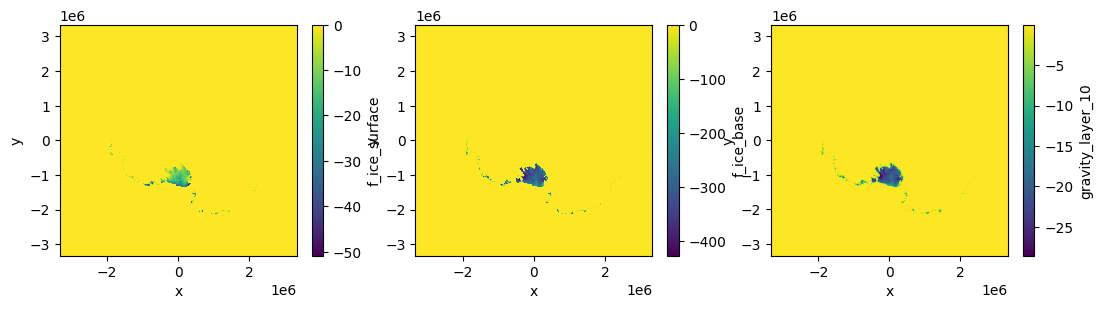

In [51]:
plt.figure(figsize = ((13, 3)))
plt.subplot(1, 3, 1)
dset_new.f_ice_surface.plot()
plt.subplot(1, 3, 2)
dset_new.f_ice_base.plot()
plt.subplot(1, 3, 3)
polar_data.gravity_layer_10.plot()


In [33]:
#Layer 11
prisms_11 = hm.prism_layer(
    coordinates=(dset_new.x.values, dset_new.y.values),
    surface=dset_new.f_ice_base,
    reference= dset_new.f_ice_bathy,
    properties={"density": (1030-2670) * np.ones_like(dset_new.ice_top)},)
#prisms_1
gravity_11 = prisms_11.prism_layer.gravity(coordinates, field="g_z")




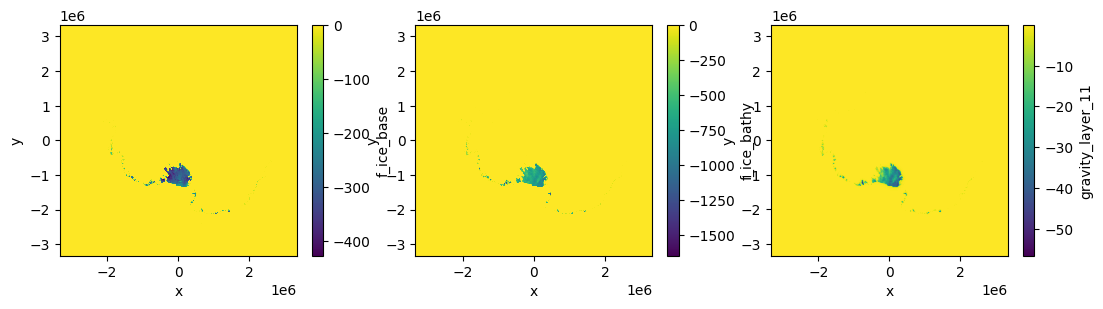

In [52]:
polar_data["gravity_layer_11"] = (("y", "x"),gravity_11)
plt.figure(figsize = ((13, 3)))
plt.subplot(1, 3, 1)
dset_new.f_ice_base.plot()
plt.subplot(1, 3, 2)
dset_new.f_ice_bathy.plot()
plt.subplot(1, 3, 3)
polar_data.gravity_layer_11.plot()

In [34]:
gravity_all=gravity_1+gravity_2+gravity_3+gravity_4+gravity_5+gravity_6+gravity_7+gravity_8+gravity_9+gravity_10+gravity_11

In [36]:
polar_data["gravity_final"] = (("y", "x"),gravity_all)

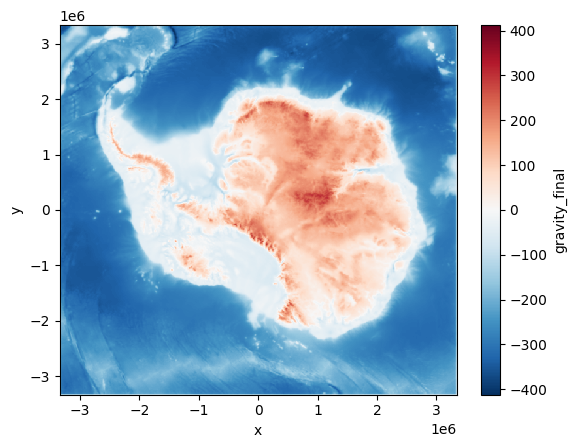

In [37]:
polar_data["gravity_final"] = (("y", "x"),gravity_all)
polar_data.gravity_final.plot()

In [39]:
polar_data["Bouguer"]=polar_data.gravity_disturbance-polar_data.gravity_final

In [41]:
Bouguer_zero=pygmt.grd2xyz(polar_data.Bouguer, output_type='numpy')
np.savetxt("Bouguer_25_07.txt", Bouguer_zero)

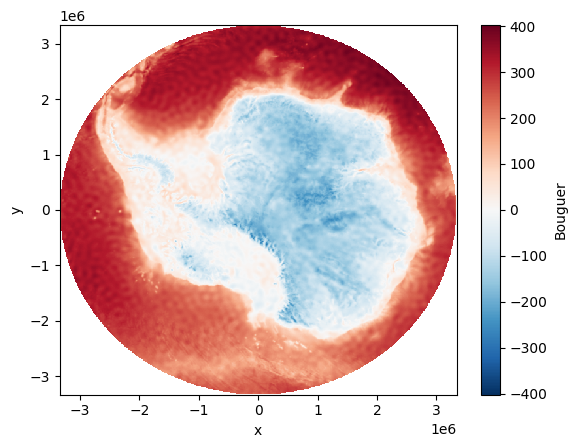

In [53]:
polar_data.Bouguer.plot()